# Spare — metrics by hand, predicting a given row, other tricks
1. Regression metrics by hand  2. Classification metrics by hand + confusion matrix
3. Predict a row the teacher gives  4. Regression → class (threshold)  5. Teacher gives a separate test file
6. Save predictions to csv  7. Multi-class

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier, RandomForestRegressor
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score, f1_score

df = pd.read_csv("../titanic.csv")
cols = ["Pclass", "Sex", "Age", "SibSp", "Parch"]
df["Sex"] = df["Sex"].map({"male": 1, "female": 0})
df = df[cols + ["Survived", "Fare"]]
df = df.fillna(df.median())
x_train, x_test, y_train, y_test = train_test_split(df[cols], df[["Survived", "Fare"]], test_size=0.2, random_state=42)
clf = GradientBoostingClassifier(random_state=42).fit(x_train, y_train["Survived"])
reg = RandomForestRegressor(300, random_state=42).fit(x_train, y_train["Fare"])
pc, pr = clf.predict(x_test), reg.predict(x_test)

## 1. Regression metrics by hand

In [2]:
y, p = y_test["Fare"].values, pr
mse = ((y - p) ** 2).mean()
rmse = np.sqrt(mse)
mae = np.abs(y - p).mean()
r2 = 1 - ((y - p) ** 2).sum() / ((y - y.mean()) ** 2).sum()
print(f"MSE {mse:.2f} | RMSE {rmse:.2f} | MAE {mae:.2f} | R2 {r2:.4f}")

MSE 1084.39 | RMSE 32.93 | MAE 13.76 | R2 0.2992


## 2. Classification metrics by hand

TP 53 TN 96 FP 9 FN 21
accuracy 0.8324 | precision 0.8548 | recall 0.7162 | F1 0.7794
sklearn check: 0.8324 0.7794
              precision    recall  f1-score   support

           0       0.82      0.91      0.86       105
           1       0.85      0.72      0.78        74

    accuracy                           0.83       179
   macro avg       0.84      0.82      0.82       179
weighted avg       0.83      0.83      0.83       179



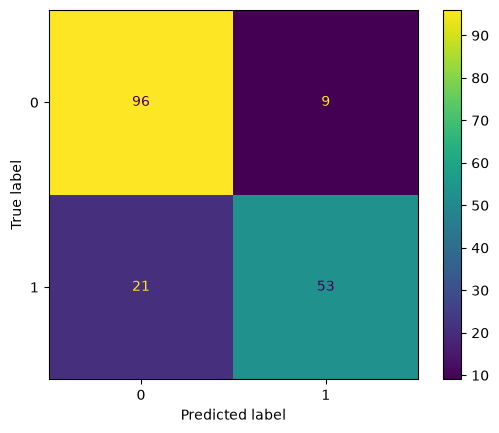

In [3]:
y = y_test["Survived"].values
tp = ((pc == 1) & (y == 1)).sum()
tn = ((pc == 0) & (y == 0)).sum()
fp = ((pc == 1) & (y == 0)).sum()
fn = ((pc == 0) & (y == 1)).sum()
accuracy = (tp + tn) / len(y)
precision = tp / (tp + fp)              # of my "yes", how many right
recall = tp / (tp + fn)                 # of real "yes", how many caught
f1 = 2 * precision * recall / (precision + recall)
print(f"TP {tp} TN {tn} FP {fp} FN {fn}")
print(f"accuracy {accuracy:.4f} | precision {precision:.4f} | recall {recall:.4f} | F1 {f1:.4f}")
print("sklearn check:", round(accuracy_score(y, pc), 4), round(f1_score(y, pc), 4))
print(classification_report(y, pc))
ConfusionMatrixDisplay.from_predictions(y, pc)
plt.show()

## 3. Predict a row the teacher gives

In [4]:
new = pd.DataFrame([{"Pclass": 1, "Sex": "female", "Age": 30, "SibSp": 0, "Parch": 0}])
new["Sex"] = new["Sex"].map({"male": 1, "female": 0})          # same cleaning as training!
new = new[cols]                                                 # same column order
print("class:", clf.predict(new)[0], "| probability:", clf.predict_proba(new)[0].round(3))
print("Fare :", round(reg.predict(new)[0], 2))
# Q2 style: add pred_class before the regressor ->  new["pred_class"] = clf.predict(new[cols])
# Q1 style (numpy): row = new.values.astype(float); then linear(x_train, y_train, row)

class: 1 | probability: [0.057 0.943]
Fare : 98.07


## 4. Regression prediction → class (threshold)

In [5]:
threshold = 30
true_cls = (y_test["Fare"] > threshold).astype(int)
pred_cls = (pr > threshold).astype(int)
print("accuracy of 'expensive' from regression:", round(accuracy_score(true_cls, pred_cls), 4))

accuracy of 'expensive' from regression: 0.8715


## 5. Teacher gives train.csv + test.csv

In [6]:
# train = pd.read_csv("train.csv"); test = pd.read_csv("test.csv")
# clean BOTH the same way (fill test with TRAIN median!):
#   med = train[cols].median()
#   train[cols] = train[cols].fillna(med); test[cols] = test[cols].fillna(med)
#   x_train, y_train = train[cols], train[target]
#   x_test,  y_test  = test[cols],  test[target]          # if test has no target -> just predict
print("pattern only")

pattern only


## 6. Save predictions

In [7]:
out = x_test.copy()
out["pred_class"] = pc
out["pred_fare"] = pr.round(2)
out.to_csv("predictions.csv", index=False)
out.head()

,Pclass,Sex,Age,SibSp,Parch,pred_class,pred_fare
709,3,1,28.0,1,1,0,17.75
439,2,1,31.0,0,0,0,12.14
840,3,1,20.0,0,0,0,7.53
720,2,0,6.0,0,1,1,23.65
39,3,0,14.0,1,0,0,13.12


## 7. Multi-class (3+ classes)

In [8]:
y3 = pd.qcut(df["Fare"], 3, labels=[0, 1, 2]).astype(int)          # cheap / mid / expensive
a, b, c, d = train_test_split(df[cols], y3, test_size=0.2, random_state=42, stratify=y3)
p = GradientBoostingClassifier(random_state=42).fit(a, c).predict(b)
print("accuracy", round(accuracy_score(d, p), 4), "| F1 macro", round(f1_score(d, p, average="macro"), 4))
# binary F1 -> f1_score(y, p) ; 3+ classes -> f1_score(y, p, average="macro")

accuracy 0.8827 | F1 macro 0.8826
